# 01 – Données et features : Bitcoin (BTCUSDT), bougies de 8 h

**Objectif :** télécharger les bougies de **8 heures** du Bitcoin (**1 jour = 3 lignes** : 00h, 08h, 16h UTC), contrôler leur qualité, ne garder que les jours complets, construire les features, découper en train / test et sauvegarder ce dont le notebook HMM a besoin.

**Exécuter le notebook de haut en bas.** Chaque cellule de code est précédée d'une courte description et suivie d'une **interprétation** du résultat.

| Étape | Cellules | Sortie |
|---|---|---|
| 1. Paramètres | 1–2 | bibliothèques, paramètres, contrôle de `src/fonctions.py` |
| 2. Téléchargement | 3 | `data/btcusdt_8h.csv` |
| 3. Qualité | 4–6 | tableau de contrôle, trous, jours complets (3 lignes / jour) |
| 4. Features | 7–10 | features, test ADF, corrélations |
| 5. Normalité | 11–12 | tests de normalité, histogrammes, QQ-plots (`results/normalite_avant.png`) |
| 6. Découpage, transformation gaussienne, sauvegarde | 13–17 | `data/btcusdt_features.csv`, `_X_train.csv`, `_X_test.csv`, `_scaler.joblib`, `results/normalite_apres.png` |
| 7. Vérification | 18 | `TOUS LES CONTRÔLES SONT OK` |

## 1. Paramètres

### Cellule 1 – Bibliothèques et paramètres
Tous les paramètres sont **au même endroit** : actif, dates, fenêtres des indicateurs, jeu de features, proportion train / test.

Les fenêtres journalières sont multipliées par 3 (3 bougies par jour) : volatilité 20 jours → 60, RSI 14 jours → 42, MACD 12/26/9 → 36/78/27.

In [1]:
import sys, os, warnings
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib
from statsmodels.tsa.stattools import adfuller
from scipy import stats
from sklearn.preprocessing import QuantileTransformer
from fonctions import *

warnings.filterwarnings("ignore", category=FutureWarning)

# --- données : Bitcoin uniquement, bougies de 8 h
SYMBOLE     = "BTCUSDT"
FICHIER     = "../data/btcusdt_8h.csv"
DEBUT, FIN  = "2017-08-17", "2026-11-01"     # période [DEBUT, FIN[
TELECHARGER = False                          # True = re-télécharger ; False = réutiliser data/btcusdt_8h.csv

# --- fenêtres des indicateurs (bougies de 8 h)
PAR_JOUR = 3                                 # 1 jour = 3 lignes
FEN_VOL, FEN_RSI, MACD = 60, 42, (36, 78, 27)

# --- jeu de features et découpage
JEUX = {"base":   ["rendement", "volatilite"],                      # jeu de base
        "etendu": ["rendement", "volatilite", "RSI", "vol_rel"]}    # jeu étendu
JEU = "base"                                                        # "base" ou "etendu"
CHOIX = JEUX[JEU]
TRAIN_FRAC = 0.7                                                    # découpage chronologique, sans mélange

for dossier in ("../data", "../results"):
    os.makedirs(dossier, exist_ok=True)
print("Jeu de features :", JEU, CHOIX)

Jeu de features : base ['rendement', 'volatilite']


> **Interprétation :**
>
> On a fixé tous les réglages au même endroit. On travaille seulement sur le **Bitcoin**, avec une bougie toutes les **8 heures** (3 par jour). Pour l'instant, le HMM utilisera 2 variables : le **rendement** et la **volatilité**.

### Cellule 2 – Contrôle de `src/fonctions.py`
S'arrête avec un **message clair** s'il manque une fonction (cause typique : ancien `fonctions.py`, ou noyau non redémarré après modification).

In [2]:
requises = ["charger_binance", "garder_jours_complets", "calculer_rendement_log",
            "calculer_volatilite", "calculer_RSI", "calculer_MACD", "construire_features"]
manquantes = [f for f in requises if f not in globals()]
assert not manquantes, (f"Manquant dans src/fonctions.py : {manquantes}. "
                        "Mettre à jour src/fonctions.py puis Kernel > Restart.")
print("fonctions.py OK")

fonctions.py OK


> **Interprétation :**
>
> Toutes les fonctions nécessaires existent dans `fonctions.py`. On peut continuer sans risque d'erreur.

## 2. Téléchargement

### Cellule 3 – Bougies de 8 h du Bitcoin
API publique Binance (1000 bougies par requête, avec pagination), prix en USDT, heures en UTC. Avec `TELECHARGER = False`, le fichier existant est réutilisé.

In [3]:
if TELECHARGER or not os.path.exists(FICHIER):
    brut = charger_binance(SYMBOLE, "8h", DEBUT, FIN)
    brut.to_csv(FICHIER)
    etat = "téléchargé"
else:
    brut = pd.read_csv(FICHIER, index_col=0, parse_dates=True)
    etat = "réutilisé"
brut = brut.sort_index()
print(f"{SYMBOLE} {etat} : {brut.shape[0]} lignes, du {brut.index[0]} au {brut.index[-1]}")

BTCUSDT réutilisé : 10087 lignes, du 2017-08-17 00:00:00 au 2026-11-01 00:00:00


> **Interprétation :**
>
> Le fichier du Bitcoin a été relu : **10 087 bougies**, du 17 août 2017 au 1er novembre 2026. On n'a pas eu besoin de tout retélécharger.

## 3. Contrôle qualité

### Cellule 4 – Tableau de contrôle
Nombre de lignes, dates, doublons, valeurs manquantes, volumes nuls, heures des bougies, et **nombre de lignes par jour** (on attend 3).

In [4]:
par_jour = brut.groupby(brut.index.normalize()).size()
pd.Series({"lignes": len(brut), "début": brut.index[0], "fin": brut.index[-1],
           "doublons": int(brut.index.duplicated().sum()), "NaN": int(brut.isna().sum().sum()),
           "volume nul": int((brut["Volume"] == 0).sum()),
           "heures des bougies": sorted(brut.index.hour.unique()),
           "jours": len(par_jour), "jours à 3 lignes": int((par_jour == 3).sum()),
           "jours incomplets": int((par_jour != 3).sum())}).to_frame("BTCUSDT 8h")

,BTCUSDT 8h
lignes,10087
début,2017-08-17 00:00:00
fin,2026-11-01 00:00:00
doublons,0
NaN,0
volume nul,0
heures des bougies,"[0, 8, 16]"
jours,3364
jours à 3 lignes,3361
jours incomplets,3


> **Interprétation :**
>
> Les données sont propres : **aucun doublon, aucune valeur manquante, aucun volume nul**. Les bougies sont bien à 00h, 08h et 16h.
> Sur 3 364 jours, **3 361 ont bien 3 lignes**. Seuls 3 jours sont incomplets : on va s'en occuper juste après.

### Cellule 5 – Où sont les trous ?
Un trou = un pas de temps supérieur à 8 h. Les jours incomplets correspondent à une panne de Binance (février 2018) et, éventuellement, à un dernier jour tronqué.

In [5]:
pas = brut.index.to_series().diff()
trous = pas[pas > pd.Timedelta("8h")]
display(pd.DataFrame({"bougie après le trou": trous.index, "trou": trous.values,
                      "bougies manquantes": (trous / pd.Timedelta("8h") - 1).round().astype(int).values}))
print("Jours incomplets :")
print(par_jour[par_jour != 3].to_string())

,bougie après le trou,trou,bougies manquantes
0,2018-02-09 08:00:00,1 days 08:00:00,3


Jours incomplets :
Date
2018-02-08    1
2018-02-09    2
2026-11-01    1


> **Interprétation :**
>
> Il n'y a qu'**un seul trou** : en février 2018, Binance a été en panne et **3 bougies manquent**. C'est ce qui rend les journées du 8 et du 9 février incomplètes.
> Le 1er novembre 2026 n'a qu'une bougie, car les données s'arrêtent ce jour-là à 00h.

### Cellule 6 – Garder uniquement les jours complets (1 jour = 3 lignes)
`garder_jours_complets` supprime les jours qui n'ont pas exactement 3 bougies. On perd une poignée de lignes, mais chaque jour du jeu de données a désormais la même structure (00h, 08h, 16h).

In [6]:
df = garder_jours_complets(brut, PAR_JOUR)
nb_par_jour = df.groupby(df.index.normalize()).size()
assert (nb_par_jour == 3).all(), "il reste des jours incomplets"
assert len(df) % 3 == 0 and (df.index.hour.values.reshape(-1, 3) == [0, 8, 16]).all()
print(f"Lignes : {len(brut)} -> {len(df)} ({len(brut) - len(df)} supprimées) | {len(nb_par_jour)} jours x 3 lignes")

Lignes : 10087 -> 10083 (4 supprimées) | 3361 jours x 3 lignes


> **Interprétation :**
>
> On a supprimé les 3 jours incomplets, soit **seulement 4 lignes sur 10 087**. Désormais, **chaque jour a exactement 3 lignes** (00h, 08h, 16h). C'est la règle « 1 jour = 3 lignes » demandée.

## 4. Features

### Cellule 7 – Effet de session sur le volume (justifie `vol_rel`)
Les bougies de 00h, 08h et 16h n'ont pas le même volume. Une simple variation de volume mesure donc surtout *quelle bougie de la journée c'est*. `vol_rel` compare chaque bougie au volume moyen de **la même session sur les 20 derniers jours** (passé uniquement).

Lecture : la première colonne montre un effet de session net ; la seconde doit être **à peu près égale** entre les sessions.

In [7]:
h = df.index.hour
dv = np.log1p(df["Volume"]).diff()
v_session = df["Volume"].groupby(h).transform(lambda s: s.rolling(20).mean().shift(1))
vol_rel = np.log(df["Volume"] / v_session).replace([np.inf, -np.inf], np.nan)

pd.DataFrame({"variation moyenne du log-volume": dv.groupby(h).mean(),
              "vol_rel moyen (utilisé)": vol_rel.groupby(h).mean()}).rename_axis("session (h UTC)").round(2)

,variation moyenne du log-volume,vol_rel moyen (utilisé)
session (h UTC),,
0,-0.12,-0.11
8,0.30,-0.10
16,-0.18,-0.11


> **Interprétation :**
>
> **1re colonne :** le volume monte fortement dans la bougie de 08h (+0,30) et baisse dans les autres. Le volume dépend donc surtout de **l'heure de la journée**, pas du marché.
> **2e colonne :** avec `vol_rel`, les 3 sessions sont presque égales (−0,10 à −0,11). L'effet de l'heure a disparu, et `vol_rel` mesure vraiment si le marché est plus actif que d'habitude.

### Cellule 8 – Calcul des features
`construire_features` (dans `src/fonctions.py`) : `rendement` (log), `volatilite` (écart-type glissant, 60 bougies), `RSI` (42), `MACD_norm` et `histo_norm` (MACD / prix), `amplitude` ((High−Low)/Close), `vol_rel`. Les premières lignes ont des `NaN` à cause des fenêtres glissantes : elles sont supprimées, ainsi que le premier jour s'il devient incomplet.

In [8]:
feat = construire_features(df, FEN_VOL, FEN_RSI, MACD)
print("NaN créés par les fenêtres :")
print(feat.isna().sum().to_string())
feat = garder_jours_complets(feat.dropna(), PAR_JOUR)
print("\nLignes gardées :", len(feat), "sur", len(df), f"({len(feat) // 3} jours complets)")
feat.describe().T.round(4)

NaN créés par les fenêtres :
rendement      1
volatilite    60
RSI           42
MACD_norm      0
histo_norm     0
amplitude      0
vol_rel       60



Lignes gardées : 10023 sur 10083 (3341 jours complets)


,count,mean,std,min,25%,50%,75%,max
rendement,10023.0,0.0003,0.0200,-0.2449,-0.0070,0.0004,0.0078,0.1961
volatilite,10023.0,0.0179,0.0091,0.0041,0.0118,0.0158,0.0210,0.0576
RSI,10023.0,51.4594,8.6684,20.1020,45.8372,50.5259,56.9756,81.3347
MACD_norm,10023.0,0.0012,0.0427,-0.2187,-0.0192,0.0019,0.0271,0.1439
histo_norm,10023.0,0.0001,0.0129,-0.0875,-0.0064,0.0004,0.0078,0.0459
amplitude,10023.0,0.0276,0.0238,0.0015,0.0134,0.0211,0.0336,0.3792
vol_rel,10023.0,-0.1070,0.5413,-2.6287,-0.4222,-0.1115,0.2141,2.4597


> **Interprétation :**
>
> Les premières lignes sont perdues à cause des fenêtres glissantes : il faut 60 bougies de passé pour calculer la volatilité. On garde **10 023 lignes, soit 3 341 jours complets**.
> Le rendement moyen est presque nul (0,03 % par bougie), mais il varie beaucoup (écart-type de 2 %). Le Bitcoin bouge beaucoup, sans direction claire à court terme.

### Cellule 9 – Test de stationnarité (ADF)
Test de Dickey-Fuller augmenté sur chaque feature. **p < 0,05 → stationnaire** (pas de racine unitaire) : c'est pourquoi on modélise les rendements et non les prix. Remarque : l'ADF ne dit pas que la *variance* est constante ; les grappes de volatilité restent, et c'est justement ce que capte le HMM.

In [9]:
res = []
for c in feat.columns:
    p = adfuller(feat[c], autolag="AIC")[1]
    res.append({"variable": c, "p_value": p, "stationnaire (p<0,05)": p < 0.05})
pd.DataFrame(res).style.format({"p_value": "{:.2e}"})

,variable,p_value,"stationnaire (p<0,05)"
0,rendement,0.00e+00,True
1,volatilite,2.09e-07,True
2,RSI,1.31e-13,True
3,MACD_norm,3.49e-12,True
4,histo_norm,2.62e-28,True
5,amplitude,3.37e-12,True
6,vol_rel,2.16e-27,True


> **Interprétation :**
>
> Toutes les variables ont une **p-value bien inférieure à 0,05** : elles sont toutes **stationnaires**. Leur comportement moyen ne dérive pas dans le temps, contrairement au prix.
> C'est la condition pour pouvoir les utiliser dans un modèle comme le HMM.

### Cellule 10 – Corrélation entre features
Heatmap + liste des paires avec |corrélation| > 0,7. Deux features presque identiques rendent un HMM à covariance pleine instable : on n'en garde **qu'une** par paire. Sauvegardé dans `results/correlation_features.png`.

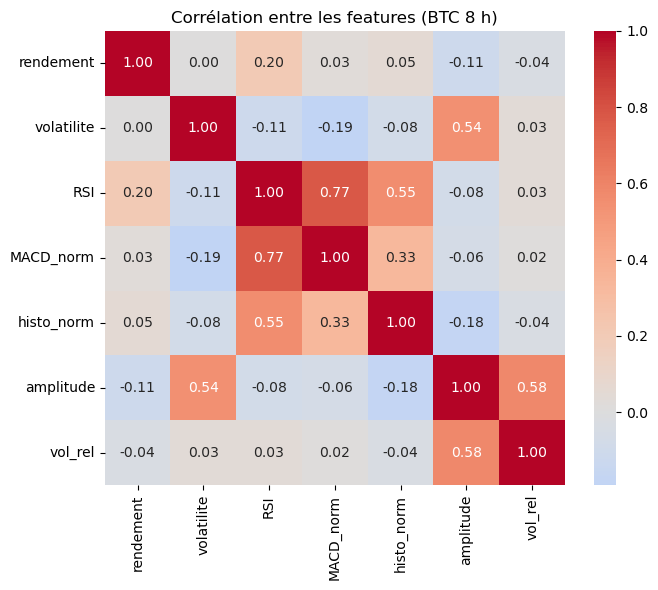

Paires avec |corr| > 0,7 : [('RSI', 'MACD_norm', 0.77)]


In [10]:
corr = feat.corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation entre les features (BTC 8 h)")
plt.tight_layout()
plt.savefig("../results/correlation_features.png", dpi=150)
plt.show()

forts = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns)
         for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.7]
print("Paires avec |corr| > 0,7 :", forts)

> **Interprétation :**
>
> La seule paire très corrélée est **RSI / MACD_norm (0,77)** : les deux mesurent la tendance récente. Il ne faut donc pas les mettre ensemble dans le HMM.
> Le **rendement et la volatilité ne sont pas corrélés (0,00)** : ils apportent deux informations différentes. C'est un bon choix pour le HMM.
> L'amplitude est liée à la volatilité (0,54) et au volume relatif (0,58) : quand le marché bouge beaucoup, les bougies sont grandes et les volumes élevés.

## 5. Normalité des features

### Cellule 11 – Les features suivent-elles une loi normale ?
Pour chaque feature : **asymétrie** (skewness, 0 pour une loi normale), **kurtosis en excès** (0 pour une loi normale ; > 0 = queues épaisses), tests de **Jarque-Bera** et de **Kolmogorov-Smirnov** (**p < 0,05 → on rejette la loi normale**), et la part des valeurs à plus de 3 écarts-types (0,27 % pour une loi normale).

In [11]:
def tableau_normalite(D):
    """Asymétrie, kurtosis en excès, tests de normalité et part des valeurs extrêmes pour chaque colonne."""
    lignes = []
    for c in D.columns:
        x = np.asarray(D[c], dtype=float)
        z = (x - x.mean()) / x.std()
        p_jb = stats.jarque_bera(x).pvalue
        lignes.append({"variable": c, "asymétrie": stats.skew(x), "kurtosis en excès": stats.kurtosis(x),
                       "p Jarque-Bera": p_jb, "p KS": stats.kstest(z, "norm").pvalue,
                       "% au-delà de 3σ": 100 * np.mean(np.abs(z) > 3), "normale (p JB > 0,05)": p_jb > 0.05})
    return pd.DataFrame(lignes).set_index("variable")

FORMAT = {"asymétrie": "{:.2f}", "kurtosis en excès": "{:.2f}", "p Jarque-Bera": "{:.1e}",
          "p KS": "{:.1e}", "% au-delà de 3σ": "{:.2f}"}
tableau_normalite(feat).style.format(FORMAT)

,asymétrie,kurtosis en excès,p Jarque-Bera,p KS,% au-delà de 3σ,"normale (p JB > 0,05)"
variable,,,,,,
rendement,-0.32,12.43,0.0e+00,3.4e-108,1.99,False
volatilite,1.92,4.68,0.0e+00,5.2e-123,2.79,False
RSI,0.29,0.29,2.7e-38,6.1e-17,0.43,False
MACD_norm,-0.71,2.25,0.0e+00,9.1e-41,1.84,False
histo_norm,-0.72,3.07,0.0e+00,9.4e-37,1.35,False
amplitude,3.72,25.93,0.0e+00,4.9e-207,1.79,False
vol_rel,0.06,1.04,1.8e-100,9.3e-09,0.84,False


> **Interprétation :**
>
> **Aucune feature ne suit une loi normale** : pour les 7 variables, les p-values de Jarque-Bera et de Kolmogorov-Smirnov sont pratiquement nulles, donc on rejette la loi normale.
> - **Rendement :** asymétrie faible (−0,32) mais **kurtosis en excès de 12,4** (0 pour une loi normale). Près de **2 % des bougies dépassent 3 écarts-types**, soit **7 fois plus** qu'avec une loi normale (0,27 %). Le Bitcoin a des **queues épaisses** : les krachs et les envolées sont beaucoup plus fréquents que ne le prévoit une courbe en cloche.
> - **Volatilité (1,92) et amplitude (3,72) :** fortement **asymétriques à droite**. Elles sont toujours positives, avec beaucoup de valeurs faibles et quelques valeurs très fortes (périodes de panique).
> - **RSI** est la variable la plus proche d'une loi normale (asymétrie et kurtosis ≈ 0,3), mais l'échantillon est si grand (10 023 lignes) que même ce petit écart est détecté par les tests.
>
> Conclusion : il faut **transformer les données** avant le HMM gaussien.

### Cellule 12 – Histogrammes et QQ-plots des features du HMM (avant transformation)
En haut : histogramme comparé à la courbe de la loi normale de même moyenne et même écart-type. En bas : **QQ-plot** ; si la loi est normale, les points sont **sur la droite rouge**. Sauvegardé dans `results/normalite_avant.png`.

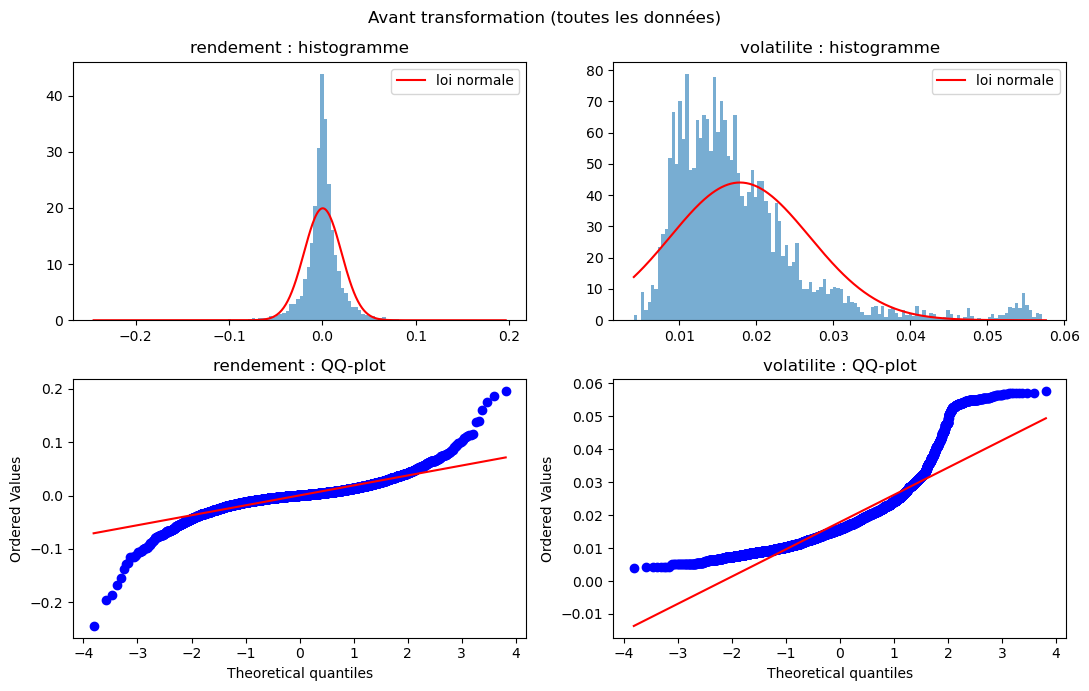

In [12]:
def graphe_normalite(D, titre, fichier):
    """Histogramme + densité normale (ligne 1) et QQ-plot (ligne 2) pour chaque colonne de D."""
    fig, axes = plt.subplots(2, D.shape[1], figsize=(5.5 * D.shape[1], 7), squeeze=False)
    for j, c in enumerate(D.columns):
        x = np.asarray(D[c], dtype=float)
        g = np.linspace(x.min(), x.max(), 400)
        axes[0, j].hist(x, bins=120, density=True, alpha=0.6)
        axes[0, j].plot(g, stats.norm.pdf(g, x.mean(), x.std()), "r", label="loi normale")
        axes[0, j].set_title(f"{c} : histogramme"); axes[0, j].legend()
        stats.probplot(x, dist="norm", plot=axes[1, j]); axes[1, j].set_title(f"{c} : QQ-plot")
    fig.suptitle(titre); plt.tight_layout(); plt.savefig(fichier, dpi=150); plt.show()

graphe_normalite(feat[CHOIX], "Avant transformation (toutes les données)", "../results/normalite_avant.png")

> **Interprétation :**
>
> Les graphiques confirment les tests :
> - **Rendement :** l'histogramme est **beaucoup plus pointu** au centre que la courbe rouge, et les QQ-plots s'écartent de la droite aux deux extrémités (forme en « S ») : ce sont les **queues épaisses**.
> - **Volatilité :** l'histogramme est **décalé à gauche avec une longue queue à droite**, et on voit un petit paquet de valeurs vers 0,055 (la période agitée de fin 2017 - début 2018). Le QQ-plot est très loin de la droite.
>
> Avec ces données brutes, l'hypothèse « observations gaussiennes » du `GaussianHMM` n'est pas respectée.

### Cellule 13 – Découpage chronologique et transformation gaussienne
Les premiers 70 % des **jours** vont dans le train, les derniers 30 % dans le test : la coupure tombe entre la bougie de 16h et celle de 00h, jamais au milieu d'une journée.

On a vu juste avant que les features **ne suivent pas une loi normale**. Or le HMM utilisé (`GaussianHMM`) suppose des observations **gaussiennes** dans chaque état. On remplace donc la simple standardisation par une **transformation par quantiles vers la loi normale** (`QuantileTransformer(output_distribution="normal")`) :
1. chaque valeur est remplacée par son rang, c'est-à-dire sa fonction de répartition empirique `F(x)`, entre 0 et 1 ;
2. ce rang est envoyé dans l'inverse de la fonction de répartition de la loi normale : `z = Φ⁻¹(F(x))`.

Le résultat suit une loi **N(0, 1)** sur le train. La transformation est **croissante** (l'ordre est conservé : une grosse baisse reste une grosse baisse) et **inversible** (`inverse_transform` redonne les valeurs d'origine). Elle est ajustée **sur le train uniquement** (pas de look-ahead), puis appliquée telle quelle au test.

In [13]:
X = feat[CHOIX]
k = int(len(X) // PAR_JOUR * TRAIN_FRAC) * PAR_JOUR          # coupure sur un nombre entier de jours
scaler  = QuantileTransformer(output_distribution="normal", n_quantiles=1000,
                              random_state=0).fit(X.iloc[:k])  # ajusté sur le TRAIN seulement
X_train = pd.DataFrame(scaler.transform(X.iloc[:k]), index=X.index[:k], columns=CHOIX)
X_test  = pd.DataFrame(scaler.transform(X.iloc[k:]), index=X.index[k:], columns=CHOIX)

print("train :", X_train.index[0], "->", X_train.index[-1], f"({len(X_train)} lignes = {len(X_train) // 3} jours)")
print("test  :", X_test.index[0],  "->", X_test.index[-1],  f"({len(X_test)} lignes = {len(X_test) // 3} jours)")

train : 2017-09-06 00:00:00 -> 2024-02-01 16:00:00 (7014 lignes = 2338 jours)
test  : 2024-02-02 00:00:00 -> 2026-10-31 16:00:00 (3009 lignes = 1003 jours)


> **Interprétation :**
>
> Le découpage tombe **entre deux journées** : le train finit le 1er février 2024 à 16h, le test commence le 2 février 2024 à 00h.
> - **Train : 2 338 jours** (environ 6,4 ans), pour apprendre ;
> - **Test : 1 003 jours** (environ 2,7 ans), pour évaluer sur des données jamais vues.

### Cellule 14 – Vérification : les données transformées sont-elles gaussiennes ?
Mêmes tests et mêmes graphiques, cette fois sur les données **transformées**, pour le train et pour le test. Sauvegardé dans `results/normalite_apres.png`.

TRAIN transformé


,asymétrie,kurtosis en excès,p Jarque-Bera,p KS,% au-delà de 3σ,"normale (p JB > 0,05)"
variable,,,,,,
rendement,0.00,0.12,1.1e-01,1.0e+00,0.26,True
volatilite,-0.00,0.11,1.5e-01,1.0e+00,0.26,True


TEST transformé (transformation apprise sur le train)


,asymétrie,kurtosis en excès,p Jarque-Bera,p KS,% au-delà de 3σ,"normale (p JB > 0,05)"
variable,,,,,,
rendement,0.01,-0.25,1.8e-02,3.4e-01,0.10,False
volatilite,0.26,-0.42,9.6e-13,4.6e-06,0.00,False


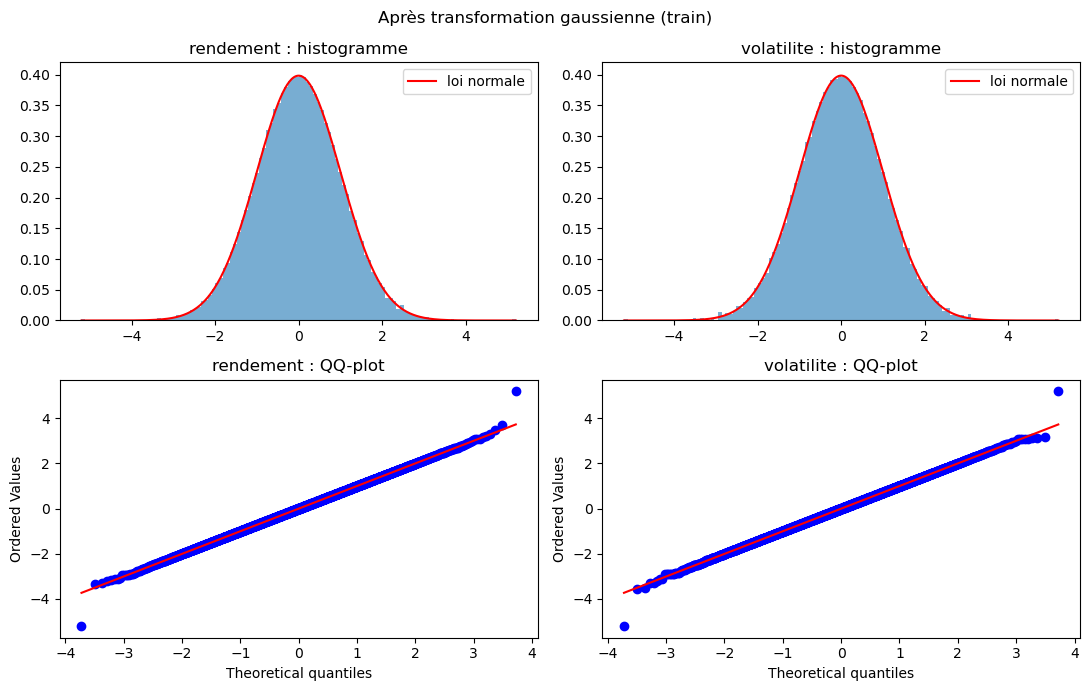

In [14]:
print("TRAIN transformé")
display(tableau_normalite(X_train).style.format(FORMAT))
print("TEST transformé (transformation apprise sur le train)")
display(tableau_normalite(X_test).style.format(FORMAT))
graphe_normalite(X_train, "Après transformation gaussienne (train)", "../results/normalite_apres.png")

> **Interprétation :**
>
> **Sur le train, les données transformées suivent une loi normale :**
> - asymétrie ≈ 0,00 et kurtosis en excès ≈ 0,1 pour les deux variables (contre 12,4 et 4,7 avant) ;
> - **p Jarque-Bera = 0,11 (rendement) et 0,15 (volatilité) > 0,05** et p KS ≈ 1 : on **ne rejette plus** la loi normale ;
> - **0,26 %** des valeurs au-delà de 3σ, exactement ce qu'attend une loi normale (0,27 %).
>
> Sur les graphiques, l'histogramme épouse la courbe rouge et les points du QQ-plot sont **alignés sur la droite**. Les deux points isolés à ±5,2 sont le minimum et le maximum du train : la transformation les envoie à l'extrémité de la loi normale.
>
> **Sur le test**, le rendement reste proche d'une loi normale (asymétrie 0,01, kurtosis −0,25, p KS = 0,34). La volatilité, elle, est rejetée (p ≈ 0) : ce n'est pas un défaut de la transformation, c'est que **2024-2026 est une période calme**. Le test n'occupe que la partie basse de la distribution du train (volatilité transformée entre −2,2 et 0,8). La transformation est apprise sur le train et appliquée telle quelle, sans regarder le test : c'est le prix à payer pour éviter le look-ahead.

### Cellule 15 – Comparaison train / test
La moyenne du train vaut ≈ 0 par construction. Une moyenne du test **différente de 0** est normale et informative : elle indique à quel point la période de test diffère de la période d'apprentissage (par exemple un marché plus calme).

In [15]:
pd.DataFrame({"moyenne train": X_train.mean(), "moyenne test": X_test.mean(),
              "écart-type train": X_train.std(), "écart-type test": X_test.std()}).round(2)

,moyenne train,moyenne test,écart-type train,écart-type test
rendement,0.0,-0.02,1.0,0.79
volatilite,-0.0,-0.79,1.0,0.60


> **Interprétation :**
>
> Sur le train, moyenne 0 et écart-type 1 : c'est la loi N(0, 1) obtenue par la transformation.
> Dans le test, la volatilité moyenne vaut **−0,79** et son écart-type **0,60** au lieu de 1 : le marché de 2024-2026 est **beaucoup plus calme** que celui de 2017-2024. Le rendement du test est aussi moins dispersé (écart-type 0,79).
> C'est important pour la suite : un modèle appris sur une période agitée sera testé sur une période calme.

### Cellule 16 – Graphique des features et du découpage
Rendement, volatilité et volume relatif dans le temps, avec une ligne verticale au début du test. Sauvegardé dans `results/features_btc.png` (utile pour le rapport).

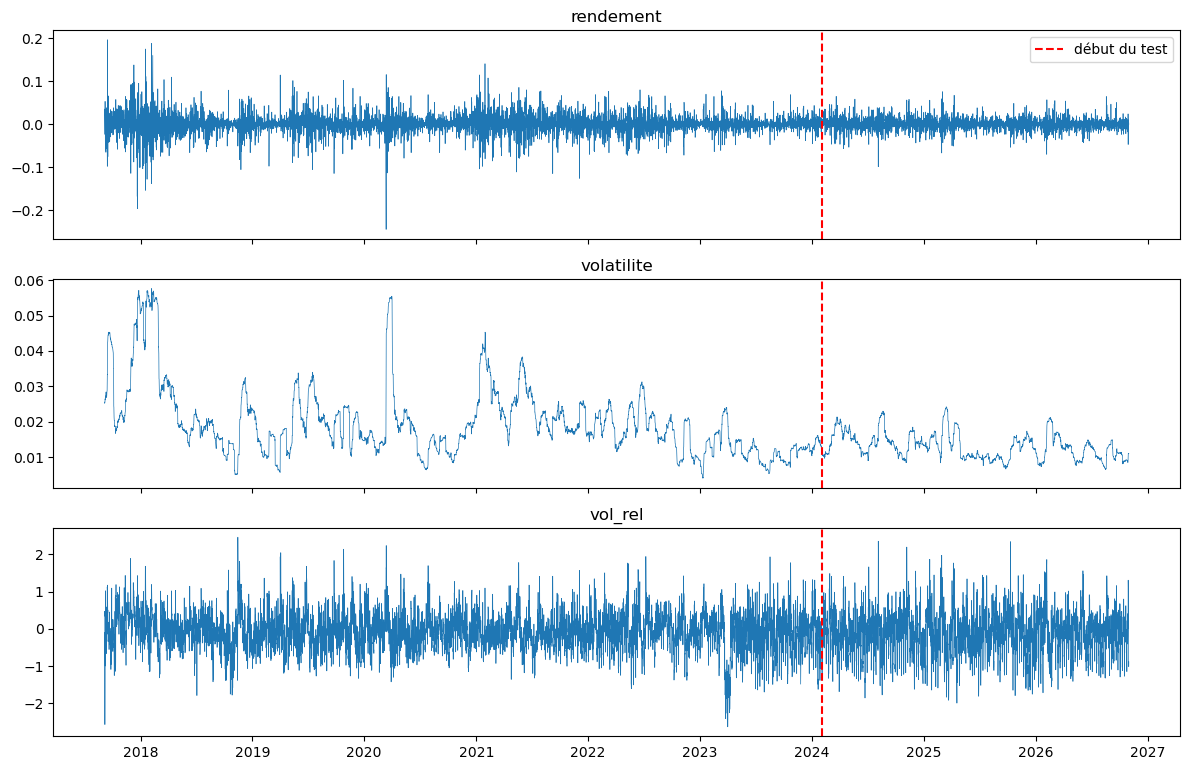

In [16]:
cols = ["rendement", "volatilite", "vol_rel"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 2.6 * len(cols)), sharex=True)
for ax, c in zip(axes, cols):
    ax.plot(feat.index, feat[c], lw=0.5)
    ax.axvline(X_test.index[0], color="red", ls="--", label="début du test")
    ax.set_title(c)
axes[0].legend()
plt.tight_layout()
plt.savefig("../results/features_btc.png", dpi=150)
plt.show()

> **Interprétation :**
>
> **Rendement :** de très grosses variations en 2017-2018 et en mars 2020 (krach du Covid), plus petites ensuite.
> **Volatilité :** des pics nets (fin 2017, mars 2020, 2021) suivis de périodes calmes. On voit des **périodes agitées et des périodes calmes qui durent** : ce sont exactement les « régimes » que le HMM doit retrouver.
> Après la ligne rouge (le test), la volatilité reste basse.

### Cellule 17 – Sauvegarde
Écrit `data/btcusdt_features.csv` (toutes les features + `Close`), `_X_train.csv`, `_X_test.csv` et `_scaler.joblib` (le transformateur gaussien, pour réutiliser exactement la même transformation, par exemple dans le dashboard).

In [17]:
feat.join(df["Close"]).to_csv("../data/btcusdt_features.csv")
X_train.to_csv("../data/btcusdt_X_train.csv")
X_test.to_csv("../data/btcusdt_X_test.csv")
joblib.dump(scaler, "../data/btcusdt_scaler.joblib")
print("Fichiers sauvegardés dans data/")

Fichiers sauvegardés dans data/


> **Interprétation :**
>
> Les 4 fichiers sont enregistrés dans `data/`. Les notebooks suivants les relisent, donc tout le monde utilise exactement les mêmes données.

## 7. Vérification finale

### Cellule 18 – Contrôle automatique des fichiers sauvegardés
Recharge les fichiers et vérifie : pas de `NaN`, mêmes colonnes que le jeu choisi et que le transformateur, dates croissantes, **le test commence après la fin du train**, et **chaque jour a exactement 3 lignes**.

In [18]:
Xtr = pd.read_csv("../data/btcusdt_X_train.csv", index_col=0, parse_dates=True)
Xte = pd.read_csv("../data/btcusdt_X_test.csv",  index_col=0, parse_dates=True)
ft  = pd.read_csv("../data/btcusdt_features.csv", index_col=0, parse_dates=True)
sc  = joblib.load("../data/btcusdt_scaler.joblib")

assert not Xtr.isna().any().any() and not Xte.isna().any().any(), "NaN dans les fichiers X"
assert list(Xtr.columns) == CHOIX == list(sc.feature_names_in_), "colonnes différentes du jeu choisi"
assert Xtr.index.is_monotonic_increasing and Xte.index.is_monotonic_increasing, "dates non triées"
assert Xtr.index[-1] < Xte.index[0], "le test doit commencer après le train"
assert set(CHOIX) <= set(ft.columns) and "Close" in ft.columns, "fichier de features incomplet"
for nom, t in [("train", Xtr), ("test", Xte), ("features", ft)]:
    assert (t.groupby(t.index.normalize()).size() == 3).all(), f"{nom} : un jour n'a pas 3 lignes"
print("TOUS LES CONTRÔLES SONT OK |", len(Xtr), "lignes train,", len(Xte), "lignes test | features :", CHOIX)

TOUS LES CONTRÔLES SONT OK | 7014 lignes train, 3009 lignes test | features : ['rendement', 'volatilite']


> **Interprétation :**
>
> Tous les contrôles passent : pas de valeur manquante, le test commence bien après le train, et **chaque jour a exactement 3 lignes**. Les données sont prêtes pour la suite.

## Étape suivante
- Notebook `02_selection_features` : quelles variables influencent chaque cible (rendement, volatilité, prix, MACD) ?
- Notebook `04_hmm_rendements` : entraîner le HMM sur `data/btcusdt_X_train.csv` (N = 2 à 5, AIC/BIC), interpréter les régimes, puis prédire le régime suivant avec le filtre forward (sans look-ahead).